# Анализ GDP per capita в 15 европейских странах

**Источник:** World Bank (World Development Indicators)  
**Период:** 2015–2024  
**Показатель:** ВВП на душу населения в текущих долларах США (`NY.GDP.PCAP.CD`)

**Цель:** сравнить 15 стран Европы по ВВП на душу населения, проверить качество исходных данных и посмотреть, как менялся показатель за выбранный период.

## 1. Загрузка данных

Данные загружаются напрямую из [API World Bank](https://datahelpdesk.worldbank.org/knowledgebase/articles/898581-api-basic-call-structures). При повторном запуске используем ранее сохранённый CSV, чтобы не делать лишние запросы.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams["figure.figsize"] = (10, 6)

countries = {
    "DEU": "Germany",
    "FRA": "France",
    "ITA": "Italy",
    "ESP": "Spain",
    "GBR": "United Kingdom",
    "NLD": "Netherlands",
    "BEL": "Belgium",
    "AUT": "Austria",
    "PRT": "Portugal",
    "POL": "Poland",
    "CZE": "Czechia",
    "DNK": "Denmark",
    "SWE": "Sweden",
    "FIN": "Finland",
    "NOR": "Norway",
}

Path("data").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)
raw_file = Path("data/world_bank_gdp_per_capita_raw.csv")

In [2]:
if raw_file.exists():
    df = pd.read_csv(raw_file)
    print("Загрузил сохранённые данные:", raw_file)
else:
    codes = ";".join(countries)
    url = f"https://api.worldbank.org/v2/country/{codes}/indicator/NY.GDP.PCAP.CD"
    params = {"format": "json", "date": "2015:2024", "per_page": 1000}

    response = requests.get(url, params=params, timeout=45)
    response.raise_for_status()
    result = response.json()

    if not isinstance(result, list) or len(result) < 2 or not isinstance(result[1], list):
        raise ValueError("World Bank API вернул неожиданный ответ")

    rows = []
    for item in result[1]:
        rows.append({
            "country_code": item["countryiso3code"],
            "year": item["date"],
            "gdp_per_capita": item["value"],
        })

    df = pd.DataFrame(rows)
    df.to_csv(raw_file, index=False)
    print("Данные скачаны и сохранены:", raw_file)

print("Размер таблицы:", df.shape)
df.head()

Данные скачаны и сохранены: data\world_bank_gdp_per_capita_raw.csv
Размер таблицы: (150, 3)


,country_code,year,gdp_per_capita
0,AUT,2024,"58,268.88"
1,AUT,2023,"56,579.50"
2,AUT,2022,"52,336.77"
3,AUT,2021,"53,648.64"
4,AUT,2020,"48,716.41"


## 2. Первичная проверка данных

Посмотрим на типы столбцов, количество пропусков и дубликатов. Для этой задачи дубликатом считаем повторение пары «страна — год».

In [3]:
df.info()
print("\nПропуски по столбцам:")
print(df.isna().sum())
print("\nПовторяющихся записей (страна + год):", df.duplicated(["country_code", "year"]).sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   country_code    150 non-null    object 
 1   year            150 non-null    object 
 2   gdp_per_capita  150 non-null    float64
dtypes: float64(1), object(2)
memory usage: 3.6+ KB

Пропуски по столбцам:
country_code      0
year              0
gdp_per_capita    0
dtype: int64

Повторяющихся записей (страна + год): 0


## 3. Подготовка таблицы

Приводим столбцы к нужным типам, удаляем повторяющиеся строки и записи без значения показателя. Отсутствующие значения не заменяем нулями: это исказило бы сравнение стран.

In [4]:
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df["gdp_per_capita"] = pd.to_numeric(df["gdp_per_capita"], errors="coerce")

df = df.drop_duplicates(subset=["country_code", "year"])
missing_before = df["gdp_per_capita"].isna().sum()
df = df.dropna(subset=["country_code", "year", "gdp_per_capita"]).copy()
df["year"] = df["year"].astype(int)
df["country"] = df["country_code"].map(countries)
df = df.sort_values(["country", "year"]).reset_index(drop=True)

print("Удалено строк с отсутствующим GDP per capita:", missing_before)
print("Размер очищенной таблицы:", df.shape)
print("Стран:", df["country_code"].nunique())
print("Период:", df["year"].min(), "—", df["year"].max())
df.head()

Удалено строк с отсутствующим GDP per capita: 0
Размер очищенной таблицы: (150, 4)
Стран: 15
Период: 2015 — 2024


,country_code,year,gdp_per_capita,country
0,AUT,2015,"43,915.23",Austria
1,AUT,2016,"45,061.50",Austria
2,AUT,2017,"47,163.74",Austria
3,AUT,2018,"51,194.07",Austria
4,AUT,2019,"49,885.99",Austria


In [5]:
# Сохраняем очищенные данные для повторного использования
clean_file = Path("data/world_bank_gdp_per_capita_clean.csv")
df.to_csv(clean_file, index=False)
print("Сохранил:", clean_file)

Сохранил: data\world_bank_gdp_per_capita_clean.csv


## 4. Сравнение стран за 2024 год

Отсортируем страны от наибольшего значения ВВП на душу населения к наименьшему.

In [6]:
latest = df[df["year"] == 2024].sort_values("gdp_per_capita", ascending=False)
print("Доступно стран за 2024 год:", len(latest))
latest[["country", "gdp_per_capita"]]

Доступно стран за 2024 год: 15


,country,gdp_per_capita
99,Norway,"89,888.95"
39,Denmark,"71,026.48"
89,Netherlands,"67,465.32"
9,Austria,"58,268.88"
139,Sweden,"57,222.71"
19,Belgium,"56,581.94"
69,Germany,"56,103.73"
149,United Kingdom,"53,341.31"
49,Finland,"53,155.55"
59,France,"46,103.08"


In [7]:
print("Описательная статистика за 2024 год (USD):")
print(latest["gdp_per_capita"].describe())

if not latest.empty:
    highest = latest.iloc[0]
    lowest = latest.iloc[-1]
    print(f"\nСамый высокий показатель: {highest['country']} — ${highest['gdp_per_capita']:,.0f}")
    print(f"Самый низкий показатель: {lowest['country']} — ${lowest['gdp_per_capita']:,.0f}")

Описательная статистика за 2024 год (USD):
count       15.00
mean    51,411.60
std     17,382.45
min     25,103.57
25%     37,878.20
50%     53,341.31
75%     57,745.79
max     89,888.95
Name: gdp_per_capita, dtype: float64

Самый высокий показатель: Norway — $89,889
Самый низкий показатель: Poland — $25,104


## 5. График: сравнение стран за 2024 год

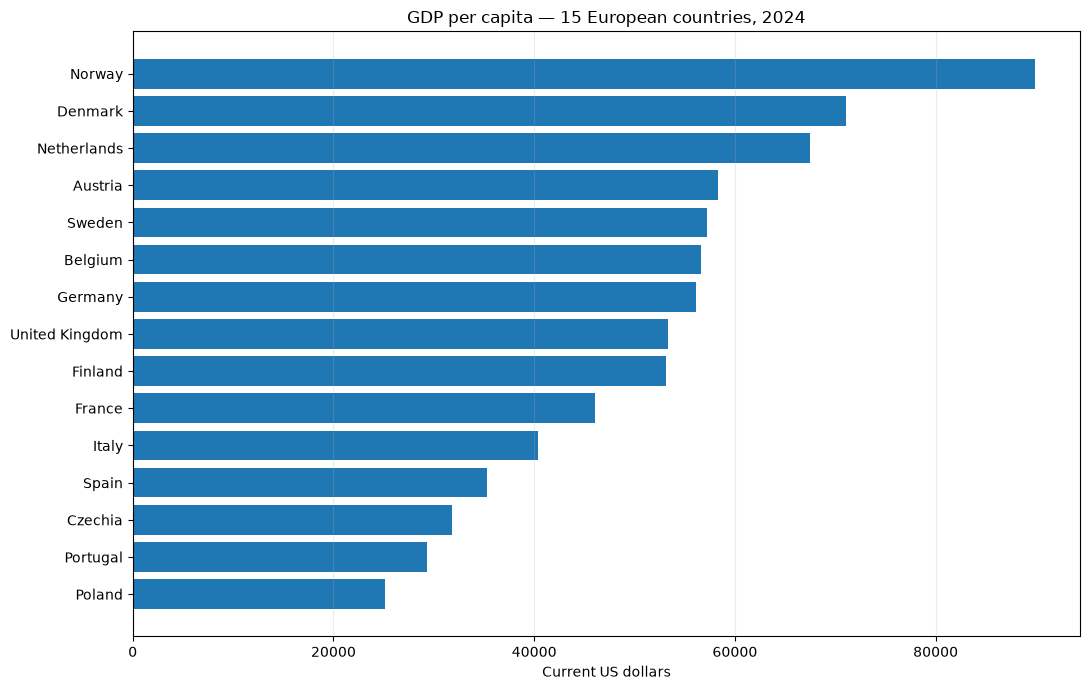

In [8]:
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(latest["country"], latest["gdp_per_capita"])
ax.invert_yaxis()
ax.set_title("GDP per capita — 15 European countries, 2024")
ax.set_xlabel("Current US dollars")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig("figures/gdp_per_capita_2024.png", dpi=160)
plt.show()

## 6. Динамика показателя

Для наглядности посмотрим на четыре страны с разным уровнем дохода.

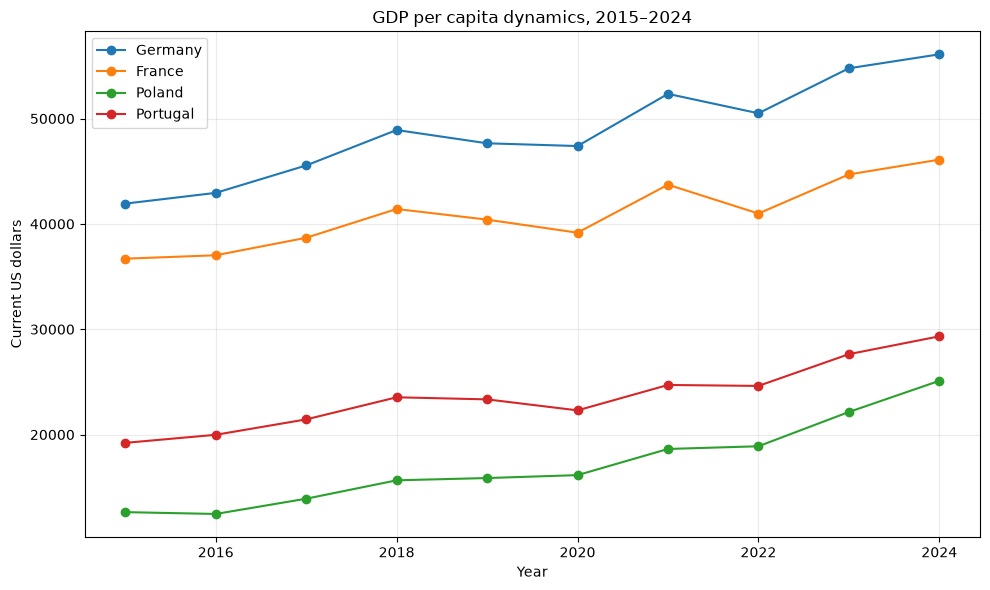

In [9]:
selected = ["Germany", "France", "Poland", "Portugal"]
trend = df[df["country"].isin(selected)]

fig, ax = plt.subplots(figsize=(10, 6))
for country in selected:
    country_data = trend[trend["country"] == country]
    ax.plot(country_data["year"], country_data["gdp_per_capita"], marker="o", label=country)

ax.set_title("GDP per capita dynamics, 2015–2024")
ax.set_xlabel("Year")
ax.set_ylabel("Current US dollars")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig("figures/gdp_per_capita_trend.png", dpi=160)
plt.show()

## 7. Сравнение 2015 и 2024 годов

Посчитаем, насколько изменился показатель в долларах США за период. Это **не равно реальному росту ВВП**, потому что показатель выражен в текущих долларах.

In [10]:
start_year = df[df["year"] == 2015].set_index("country")["gdp_per_capita"]
end_year = df[df["year"] == 2024].set_index("country")["gdp_per_capita"]
comparison = pd.concat([start_year, end_year], axis=1)
comparison.columns = ["2015", "2024"]
comparison = comparison.dropna().copy()
comparison["change_pct"] = (comparison["2024"] / comparison["2015"] - 1) * 100
comparison = comparison.sort_values("change_pct", ascending=False)
comparison.round(2)

,2015,2024,change_pct
country,,,
Poland,"12,637.52","25,103.57",98.64
Czechia,"17,931.60","31,827.76",77.50
Portugal,"19,215.78","29,328.31",52.63
Netherlands,"45,793.81","67,465.32",47.32
Belgium,"40,893.80","56,581.94",38.36
Spain,"25,982.44","35,326.77",35.96
Germany,"41,929.75","56,103.73",33.80
Denmark,"53,094.01","71,026.48",33.77
Austria,"43,915.23","58,268.88",32.68


## 8. Основные выводы

Выводы формируются по загруженным данным. Они могут незначительно измениться, если World Bank обновит статистику.

In [11]:
if not latest.empty and not comparison.empty:
    print(f"1. Среди выбранных стран наибольший GDP per capita за 2024 год — у {latest.iloc[0]['country']}.")
    print(f"2. Наименьший показатель за 2024 год — у {latest.iloc[-1]['country']}.")
    print(f"3. Медианное значение по выборке — ${latest['gdp_per_capita'].median():,.0f}.")
    print(f"4. Наибольшее относительное изменение в текущих долларах с 2015 по 2024 год — у {comparison.index[0]} ({comparison.iloc[0]['change_pct']:.1f}%).")
    print("5. Сравнение отражает номинальные долларовые значения, а не изменение реального благосостояния.")

1. Среди выбранных стран наибольший GDP per capita за 2024 год — у Norway.
2. Наименьший показатель за 2024 год — у Poland.
3. Медианное значение по выборке — $53,341.
4. Наибольшее относительное изменение в текущих долларах с 2015 по 2024 год — у Poland (98.6%).
5. Сравнение отражает номинальные долларовые значения, а не изменение реального благосостояния.


## Итог

В проекте я использовал **pandas** для загрузки и подготовки данных, проверил типы столбцов, пропуски и дубликаты, сравнил показатели 15 стран и построил два графика.

Для более корректного сравнения экономического роста во времени в будущем можно использовать показатель World Bank **GDP per capita (constant 2015 US$)** — `NY.GDP.PCAP.KD`. В этом исследовании использованы **текущие доллары США**, как явно указано в источнике.